<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-05/lab-020-j1j2-without-labels.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 020 <br>
<hr/>

# Lab 020 — The $J_1$–$J_2$ phase diagram without labels

Lab 018 introduced the frustrated $J_1$–$J_2$ Ising model and produced snapshots on a grid in the $(g,T)$ plane, $g=J_2/J_1$.
We know its physics: a ferromagnet for $g<1/2$, a stripe phase for $g>1/2$, a paramagnet at high $T$, and a transition temperature that
drops to zero at the frustrated point $g=1/2$. We also saw the two practical problems of a physicist who maps a phase diagram:

* **which quantity to plot** is not obvious: the magnetisation is blind to the stripe phase;
* **a dense scan is expensive**: fluctuation observables such as the specific heat need many samples at every grid point.

Here we treat the model as if we did not know its phases, run two unsupervised methods on the raw snapshots, and compare every output
with the known physics:

1. **PCA** on all snapshots: which patterns does it find?
2. **Autoencoder anomaly detection** (Kottmann, Huembeli, Lewenstein, Acín, Phys. Rev. Lett. **125**, 170603 (2020)): train on a small,
   well-understood corner of the phase diagram, map the reconstruction error over the whole plane, and read off boundaries.
   We do this for **three different training regimes** and compare the boundaries each of them detects.
3. **A combined map** from the three regimes.
4. **A coarse scan** with few samples, and where it tells us to measure more.

> **Running in Google Colab.** Run Lab 018 first (it writes `data/j1j2_L32.npz`), or upload that file to `data/`. The notebook runs on the CPU;
> training the three autoencoders takes a few minutes.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"
import time, json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle

import jax
import jax.numpy as jnp
import optax
from flax import nnx

print("JAX", jax.__version__, "| devices:", jax.devices())
UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
SPIN_CMAP = ListedColormap(["#FFFFFF", UJNavy])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
FIG, DATA = "../beamer/figures", "data"
os.makedirs(FIG, exist_ok=True)
NUMBERS = {}
savefig = lambda fig, name: fig.savefig(f"{FIG}/{name}", dpi=200, bbox_inches="tight")

d = np.load(f"{DATA}/j1j2_L32.npz")
L = int(d["L"]); G = d["g"]
order = np.argsort(d["T"]); T = d["T"][order]
S = (np.unpackbits(d["configs"], axis=-1, count=L).astype(np.int8) * 2 - 1)[:, order]     # (nG, nT, n, L, L)
nG, nT, nS = S.shape[:3]
print(f"{nG} couplings g in [{G.min()}, {G.max()}], {nT} temperatures T in [{T.min()}, {T.max()}], {nS} snapshots per point, L = {L}")

JAX 0.11.0 | devices: [CpuDevice(id=0)]


81 couplings g in [0.0, 1.0], 79 temperatures T in [0.1, 4.0], 100 snapshots per point, L = 32


<hr/>
## 1. The reference: what the known observables show

We recompute the three maps of Lab 018 from the same snapshots: magnetisation $\langle|m|\rangle$, stripe order parameter
$\langle m_{\rm str}\rangle$, and specific heat $c=N\,\mathrm{Var}(e)/T^2$. From the specific heat we extract the **reference boundary**:
for every $g$ the temperature of the maximum of $c$. These are the "known properties" against which every unsupervised result is judged.

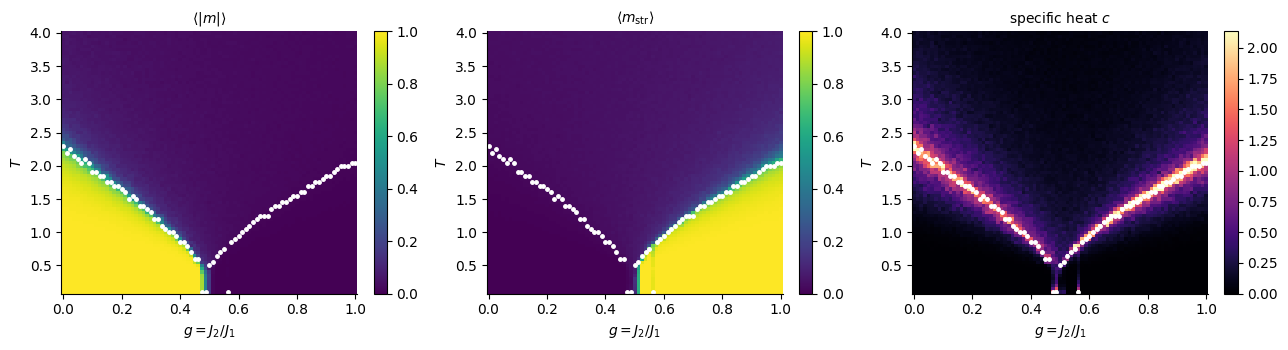

In [2]:
def local_field(s, g):
    nn = jnp.roll(s, 1, -2) + jnp.roll(s, -1, -2) + jnp.roll(s, 1, -1) + jnp.roll(s, -1, -1)
    nnn = (jnp.roll(s, (1, 1), (-2, -1)) + jnp.roll(s, (1, -1), (-2, -1))
           + jnp.roll(s, (-1, 1), (-2, -1)) + jnp.roll(s, (-1, -1), (-2, -1)))
    return nn - g * nnn

@jax.jit
def observables(s, g):
    ph = jnp.where(jnp.arange(L) % 2 == 0, 1.0, -1.0)
    m = jnp.abs(s.mean((-2, -1)))
    ms = jnp.sqrt((s * ph[:, None]).mean((-2, -1)) ** 2 + (s * ph[None, :]).mean((-2, -1)) ** 2)
    e = -0.5 * jnp.mean(s * local_field(s, g), axis=(-2, -1))
    return m.mean(-1), ms.mean(-1), e.var(-1)

obs = [observables(jnp.asarray(S[i], jnp.float32), G[i]) for i in range(nG)]
M_map, Ms_map, varE = (np.stack([np.asarray(o[k]) for o in obs]) for k in range(3))
C_map = L * L * varE / T[None, :] ** 2
T_c_ref = T[np.argmax(C_map, axis=1)]                     # specific-heat peak for every g

def draw_reference(ax, color="w", label=True):
    ax.plot(G, T_c_ref, "o", ms=2.5, color=color, label="specific-heat peak" if label else None)

def show_map(ax, Z, title, cmap="viridis", vmin=None, vmax=None, cbar_label=None):
    im = ax.pcolormesh(G, T, Z.T, shading="nearest", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xlabel("$g=J_2/J_1$"); ax.set_ylabel("$T$"); ax.set_title(title, fontsize=10)
    plt.colorbar(im, ax=ax, fraction=0.046, label=cbar_label)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
show_map(ax[0], M_map, r"$\langle|m|\rangle$", vmin=0, vmax=1)
show_map(ax[1], Ms_map, r"$\langle m_{\rm str}\rangle$", vmin=0, vmax=1)
show_map(ax[2], C_map, r"specific heat $c$", cmap="magma", vmin=0, vmax=np.percentile(C_map, 99))
for a in ax: draw_reference(a, label=False)
fig.tight_layout(); plt.show()

The specific-heat peak traces both boundaries, $T_c(g)$ falling towards $g=1/2$ from both sides. Near $g=1/2$ at low temperature the
peak position is not reliable: there the system does not order down to our lowest temperature, and $c$ shows only a broad maximum.

<hr/>
## 2. PCA on all snapshots

All snapshots from the whole grid (a subset of 20 per grid point) go into one PCA, with no information about $g$ or $T$.
We look at the leading principal components as images on the lattice, and we measure their overlap with the three candidate ordering
patterns of Lab 018: uniform $(0,0)$, stripes $(\pi,0)$ and $(0,\pi)$.

In [3]:
n_pca = 20
Xp = jnp.asarray(S[:, :, :n_pca].reshape(-1, L * L), jnp.float32)

@jax.jit
def pca(X):
    mu = X.mean(0)
    _, sv, Vt = jnp.linalg.svd(X - mu, full_matrices=False)
    return mu, sv**2 / jnp.sum(sv**2), Vt

mu, var_ratio, Vt = pca(Xp)
var_ratio, Vt = np.asarray(var_ratio), np.asarray(Vt)
x = np.arange(L)
patterns = {"uniform (0,0)": np.ones((L, L)), "stripes (pi,0)": np.outer((-1.0) ** x, np.ones(L)),
            "stripes (0,pi)": np.outer(np.ones(L), (-1.0) ** x)}
overlaps = np.array([[abs((Vt[k].reshape(L, L) * p).sum()) / L for p in patterns.values()] for k in range(6)])
print("explained variance ratio:", np.round(var_ratio[:6], 4))
for k in range(6):
    print(f"PC{k + 1}: " + "  ".join(f"{n} {o:.3f}" for n, o in zip(patterns, overlaps[k])))
NUMBERS.update(pca_var=[round(float(v), 4) for v in var_ratio[:6]],
               pca_overlaps=[[round(float(o), 3) for o in row] for row in overlaps[:4]])

explained variance ratio: [0.1659 0.0839 0.0822 0.0031 0.003  0.0028]
PC1: uniform (0,0) 1.000  stripes (pi,0) 0.001  stripes (0,pi) 0.001
PC2: uniform (0,0) 0.001  stripes (pi,0) 1.000  stripes (0,pi) 0.024
PC3: uniform (0,0) 0.001  stripes (pi,0) 0.024  stripes (0,pi) 1.000
PC4: uniform (0,0) 0.001  stripes (pi,0) 0.000  stripes (0,pi) 0.000
PC5: uniform (0,0) 0.002  stripes (pi,0) 0.000  stripes (0,pi) 0.000
PC6: uniform (0,0) 0.001  stripes (pi,0) 0.000  stripes (0,pi) 0.000


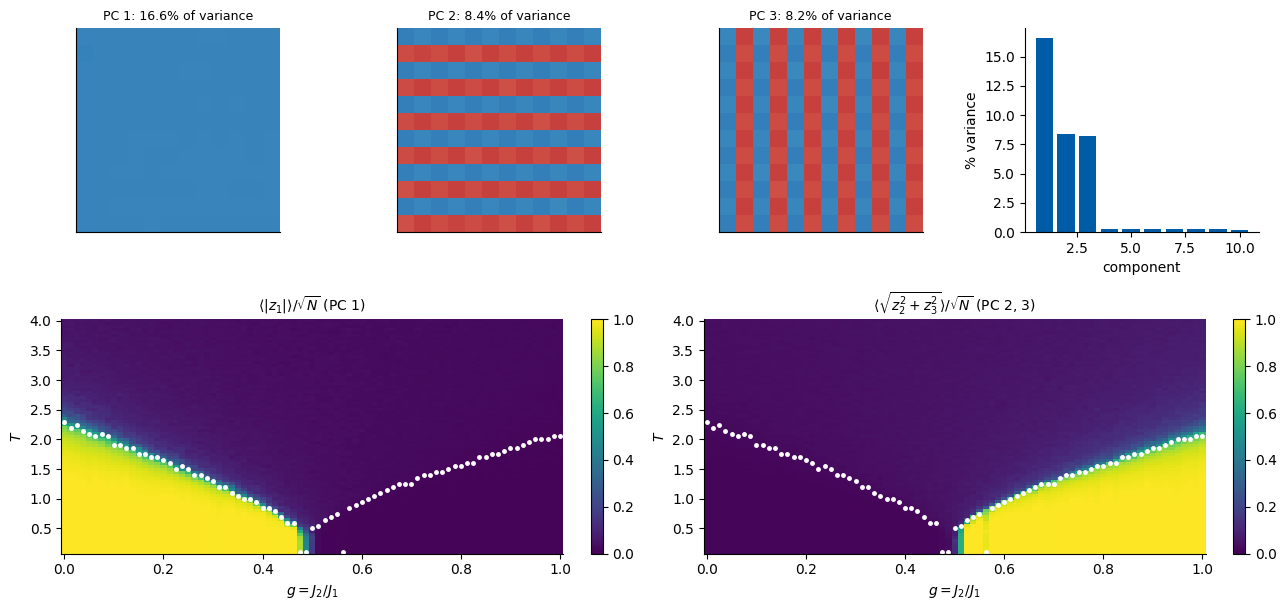

correlation of the PC maps with the known order parameters:  PC1 vs <|m|> 1.0000,  PC2,3 vs <m_str> 0.9999


In [4]:
z = np.asarray((jnp.asarray(S.reshape(-1, L * L), jnp.float32) - mu) @ Vt[:3].T).reshape(nG, nT, nS, 3) / L
pc_uniform = np.abs(z[..., 0]).mean(-1)
pc_stripe = np.sqrt(z[..., 1] ** 2 + z[..., 2] ** 2).mean(-1)

fig = plt.figure(figsize=(13, 6.2))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.15])
for k in range(3):
    a = fig.add_subplot(gs[0, k])
    a.imshow(Vt[k].reshape(L, L)[:12, :12] * L, cmap="RdBu_r", vmin=-1.5, vmax=1.5)
    a.set_title(f"PC {k + 1}: {100 * var_ratio[k]:.1f}% of variance", fontsize=9); a.set_xticks([]); a.set_yticks([])
a = fig.add_subplot(gs[0, 3])
a.bar(np.arange(1, 11), 100 * var_ratio[:10], color=UJBlue); a.set_xlabel("component"); a.set_ylabel("% variance")
a2 = fig.add_subplot(gs[1, 0:2]); show_map(a2, pc_uniform, r"$\langle|z_1|\rangle/\sqrt{N}$ (PC 1)", vmin=0, vmax=1)
a3 = fig.add_subplot(gs[1, 2:4]); show_map(a3, pc_stripe, r"$\langle\sqrt{z_2^2+z_3^2}\rangle/\sqrt{N}$ (PC 2, 3)", vmin=0, vmax=1)
for a in (a2, a3): draw_reference(a, label=False)
fig.tight_layout(); savefig(fig, "gen_j1j2_pca.png"); plt.show()
corr_u = np.corrcoef(pc_uniform.ravel(), M_map.ravel())[0, 1]; corr_s = np.corrcoef(pc_stripe.ravel(), Ms_map.ravel())[0, 1]
print(f"correlation of the PC maps with the known order parameters:  PC1 vs <|m|> {corr_u:.4f},  PC2,3 vs <m_str> {corr_s:.4f}")
NUMBERS.update(pca_corr_m=round(float(corr_u), 4), pca_corr_mstr=round(float(corr_s), 4))

**Result.** The first three principal components are the uniform pattern and the two stripe patterns (overlaps close to 1); the rest of
the spectrum is flat. Projecting on them reproduces both order-parameter maps. PCA has found the stripe order parameter, the very quantity
the magnetisation scan missed, without being told it exists.

**Why it works here, and when it would not.** Both order parameters are *linear* functions of the spins, $m=\frac1N\sum_r s_r$ and
$m_{(\pi,0)}=\frac1N\sum_r(-1)^{x}s_r$. Patterns that are linear in the data are what PCA is built to find. Order that is not linear in the
spins (vortices in the XY model, Wilson loops in gauge theories, the overlap of a spin glass) is outside its reach; Labs 021–023 test this.

**A sampling detail.** PC 2 and PC 3 carry different variance, although vertical and horizontal stripes are equivalent by symmetry. Each
annealed chain picks one orientation when it orders and keeps it; with a finite number of chains the two orientations are not sampled equally.
The difference is a property of our data set, not of the model.

<hr/>
## 3. Autoencoder anomaly maps for three training regimes

**Protocol.**
1. Choose a training region: a small rectangle in the $(g,T)$ plane where we trust our understanding.
2. Train an autoencoder on snapshots from that rectangle only.
3. Evaluate the reconstruction error $\varepsilon(\boldsymbol s)=\frac1N\lVert\boldsymbol s-\hat{\boldsymbol s}\rVert^2$ on snapshots from
   every grid point, and plot its mean as a map.
4. Read off a boundary: for every $g$, the temperature where $\log\bar\varepsilon$ changes fastest.

We repeat this for three training regions, all in corners of the plane:

| regime | region | what we know there |
|---|---|---|
| **A: ferromagnet** | $g\le0.2$, $T\le1.0$ | nearly saturated ferromagnet (weak $J_2$, low $T$) |
| **B: paramagnet** | $g\le0.2$, $T\ge3.5$ | high temperature: weakly correlated spins |
| **C: stripes** | $g\ge0.8$, $T\le1.0$ | strong $J_2$, low $T$: stripe order |

**Architecture.** A small convolutional autoencoder: two stride-2 convolutions (with periodic boundaries, like the lattice)
($32\to16\to8$), a dense bottleneck of 4 numbers, and the mirror image back, ending with $\tanh$.

**Symmetry.** The energy is unchanged when all spins flip, $H(\boldsymbol s)=H(-\boldsymbol s)$, so $\boldsymbol s$ and $-\boldsymbol s$ are
equally likely. A finite training set need not contain both signs equally often (an annealed chain orders into one of them and stays there).
We add every training snapshot also with all spins flipped: the simplest way to build a known symmetry into a network.

In [5]:
class ConvAE(nnx.Module):
    def __init__(self, latent=4, *, rngs):
        self.c1 = nnx.Conv(1, 16, (3, 3), strides=2, padding="CIRCULAR", rngs=rngs)      # 32 -> 16
        self.c2 = nnx.Conv(16, 32, (3, 3), strides=2, padding="CIRCULAR", rngs=rngs)     # 16 -> 8
        self.fe = nnx.Linear(8 * 8 * 32, latent, rngs=rngs)
        self.fd = nnx.Linear(latent, 8 * 8 * 32, rngs=rngs)
        self.d1 = nnx.ConvTranspose(32, 16, (3, 3), strides=(2, 2), padding="SAME", rngs=rngs)
        self.d2 = nnx.ConvTranspose(16, 1, (3, 3), strides=(2, 2), padding="SAME", rngs=rngs)
    def encode(self, x):
        h = nnx.relu(self.c1(x[..., None])); h = nnx.relu(self.c2(h))
        return self.fe(h.reshape(h.shape[0], -1))
    def __call__(self, x):
        h = nnx.relu(self.fd(self.encode(x))).reshape(-1, 8, 8, 32)
        return jnp.tanh(self.d2(nnx.relu(self.d1(h)))[..., 0])

@nnx.jit
def train_step(model, opt, x):
    loss, grads = nnx.value_and_grad(lambda m: jnp.mean((m(x) - x) ** 2))(model)
    opt.update(model, grads)
    return loss

@nnx.jit
def recon_error(model, x):
    return jnp.mean((model(x) - x) ** 2, axis=(-2, -1))

def train_ae(X, epochs=15, batch=64, seed=0):
    model = ConvAE(rngs=nnx.Rngs(seed))
    opt = nnx.Optimizer(model, optax.adam(1e-3), wrt=nnx.Param)
    X = jnp.asarray(np.concatenate([X, -X]), jnp.float32)  # H(s) = H(-s): every snapshot also with all spins flipped
    key = jax.random.PRNGKey(seed)
    for ep in range(epochs):
        key, k = jax.random.split(key); perm = jax.random.permutation(k, X.shape[0])
        for i in range(0, X.shape[0] - batch + 1, batch):
            loss = train_step(model, opt, X[perm[i:i + batch]])
    return model, float(loss)

N_EVAL = 20                                                # snapshots per grid point used for the maps
def spread(n_total, n):                                    # n snapshot indices spread over all chains
    return np.linspace(0, n_total - 1, n).round().astype(int)

def error_map(model, data=S, n=N_EVAL):
    idx = spread(data.shape[2], n)
    out = np.zeros(data.shape[:2])
    for i in range(data.shape[0]):
        e = recon_error(model, jnp.asarray(data[i][:, idx].reshape(-1, L, L), jnp.float32))
        out[i] = np.asarray(e).reshape(data.shape[1], n).mean(1)
    return out

def boundary_from_map(err, T_axis=T):
    # for every g: temperature of the fastest change of the error along T (midpoint between grid temperatures),
    # and the size of that change relative to the full range of the map
    d = np.abs(np.diff(err, axis=1))
    i = np.argmax(d, axis=1)
    return 0.5 * (T_axis[i] + T_axis[i + 1]), d[np.arange(len(i)), i] / (err.max() - err.min())

REGIMES = {"A: ferromagnet": dict(g=(0.0, 0.2), T=(0.0, 1.0), color=UJBlue),
           "B: paramagnet": dict(g=(0.0, 0.2), T=(3.5, 9.9), color=DSOrange),
           "C: stripes": dict(g=(0.8, 1.0), T=(0.0, 1.0), color="#2E8B57")}
N_TRAIN = 40                                               # snapshots per grid point used for training
JUMP_MIN = 0.15                                            # a boundary point needs a jump of >= 15% of the map's range

In [6]:
results = {}
for name, r in REGIMES.items():
    gi = (G >= r["g"][0] - 1e-9) & (G <= r["g"][1] + 1e-9); ti = (T >= r["T"][0] - 1e-9) & (T <= r["T"][1] + 1e-9)
    X_tr = S[gi][:, ti][:, :, spread(nS, N_TRAIN)].reshape(-1, L, L)
    t0 = time.time()
    model, loss = train_ae(X_tr)
    err = error_map(model)
    Tb, jump = boundary_from_map(err)
    results[name] = dict(model=model, err=err, Tb=Tb, jump=jump, gi=gi, ti=ti, n_train=X_tr.shape[0])
    in_err = err[np.ix_(gi, ti)].mean()
    print(f"{name:16s}: {X_tr.shape[0]:5d} training snapshots, final loss {loss:.4f}, mean error inside region {in_err:.4f}, "
          f"min/max over map {err.min():.4f}/{err.max():.4f}   ({time.time() - t0:.0f} s)")

A: ferromagnet  : 12920 training snapshots, final loss 0.0009, mean error inside region 0.0006, min/max over map 0.0000/1.9888   (169 s)


B: paramagnet   :  7480 training snapshots, final loss 0.9863, mean error inside region 0.9859, min/max over map 0.1785/1.0018   (107 s)


C: stripes      : 12920 training snapshots, final loss 0.0005, mean error inside region 0.0006, min/max over map 0.0000/2.0057   (173 s)


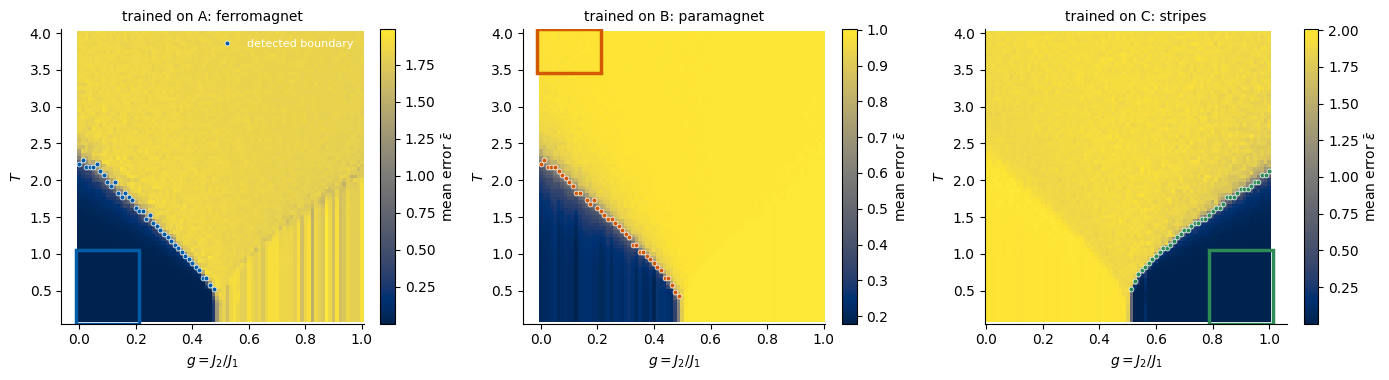

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
for a, (name, r) in zip(axes, REGIMES.items()):
    res = results[name]
    show_map(a, res["err"], f"trained on {name}", cmap="cividis", cbar_label=r"mean error $\bar\varepsilon$")
    a.add_patch(Rectangle((r["g"][0] - 0.0125, max(r["T"][0], T.min()) - 0.05), r["g"][1] - r["g"][0] + 0.025,
                          min(r["T"][1], T.max()) - max(r["T"][0], T.min()) + 0.1, fill=False, ec=r["color"], lw=2.5))
    strong = res["jump"] > JUMP_MIN
    a.plot(G[strong], res["Tb"][strong], "o", ms=3.5, color=r["color"], mec="w", mew=0.5, label="detected boundary")
    a.set_ylim(T.min() - 0.05, T.max() + 0.05)
axes[0].legend(frameon=False, fontsize=8, loc="upper right", labelcolor="w")
fig.tight_layout(); savefig(fig, "gen_j1j2_ae_maps.png"); plt.show()

**Reading the three maps.** For every $g$ the boundary point is the temperature where the mean error changes fastest; it is drawn only
if that change is at least 15% of the full range of the map.

* **A (trained on the ferromagnet):** the ferromagnetic region is reconstructed almost perfectly; its boundary $T_c(g)$ for $g<1/2$ is a
  sharp edge that falls towards $g=1/2$. Everything else, paramagnet *and* stripes, is "not ferromagnet" with similar large errors.
  This regime cannot separate the stripe phase from the paramagnet.
* **B (trained on the paramagnet):** an autoencoder trained on nearly uncorrelated spins learns little more than the average, and its error
  is large everywhere. Ferromagnetic snapshots are reconstructed *better* than the training data, so the ferromagnetic boundary is visible
  as a drop of the error. The stripe phase is **invisible**: its error is the same as in the paramagnet.
* **C (trained on the stripes):** the stripe region is reconstructed well, and its boundary $T_c(g)$ for $g>1/2$ appears. The ferromagnet
  and the paramagnet are both anomalous.

One training region answers one question: *is this snapshot like my training data?* It cannot tell two different anomalies apart.

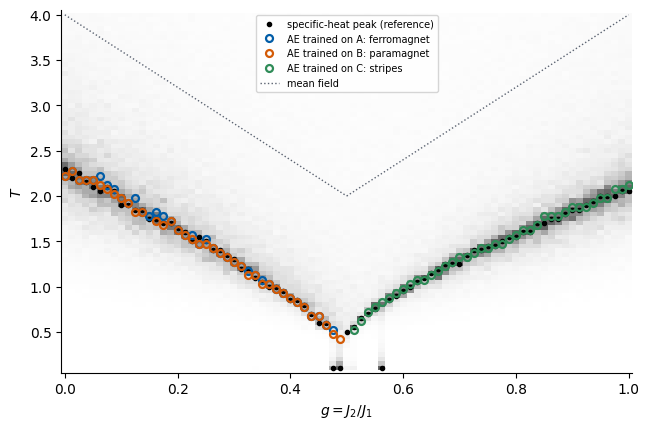

A: ferromagnet  : {'n_points': 39, 'median_abs_dev': 0.025, 'g_range': [0.0, 0.475]}
B: paramagnet   : {'n_points': 39, 'median_abs_dev': 0.025, 'g_range': [0.0, 0.4875]}
C: stripes      : {'n_points': 40, 'median_abs_dev': 0.025, 'g_range': [0.5125, 1.0]}


In [8]:
fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.pcolormesh(G, T, C_map.T, shading="nearest", cmap="Greys", vmin=0, vmax=np.percentile(C_map, 99), alpha=0.6)
ax.plot(G, T_c_ref, "k.", ms=6, label="specific-heat peak (reference)")
for name, r in REGIMES.items():
    res = results[name]; strong = res["jump"] > JUMP_MIN
    ax.plot(G[strong], res["Tb"][strong], "o", ms=5, mfc="none", mec=r["color"], mew=1.6, label=f"AE trained on {name}")
gg = np.linspace(0, 1, 101)
ax.plot(gg[gg <= 0.5], 4 * (1 - gg[gg <= 0.5]), ":", color=UJGray, lw=1); ax.plot(gg[gg >= 0.5], 4 * gg[gg >= 0.5], ":", color=UJGray, lw=1, label="mean field")
ax.set_xlabel("$g=J_2/J_1$"); ax.set_ylabel("$T$"); ax.set_ylim(T.min() - 0.05, T.max() + 0.05)
ax.legend(frameon=True, fontsize=7, loc="upper center")
fig.tight_layout(); savefig(fig, "gen_j1j2_ae_boundaries.png"); plt.show()

agree = {}
for name in REGIMES:
    res = results[name]; strong = res["jump"] > JUMP_MIN
    dev = np.abs(res["Tb"][strong] - T_c_ref[strong])
    agree[name] = dict(n_points=int(strong.sum()), median_abs_dev=round(float(np.median(dev)), 3) if strong.any() else None,
                       g_range=[float(G[strong].min()), float(G[strong].max())] if strong.any() else None)
    print(f"{name:16s}: {agree[name]}")
NUMBERS["ae_boundary_vs_C"] = agree

**Comparison with the known physics.** Where an autoencoder detects a boundary, it lies on the specific-heat ridge, to within the grid spacing
in temperature ($\Delta T=0.05$); the median deviations are printed above. Each regime sees only the boundaries of its own phase:
A and B find the ferromagnetic line, C finds the stripe line. None of them is reliable close to $g=1/2$, where the transition temperature
goes to zero and no phase is fully developed within our temperature range. Mean-field theory (dotted) is far off for every $g$.

<hr/>
## 4. Combining the regimes

Each trained autoencoder defines a "normal" level of its reconstruction error, measured on its own training region. For grid point
$(g,T)$ and regime $k$ we compute an **anomaly score**: how far the mean error lies from that level, in units of its spread,
$$
a_k(g,T) = \frac{\left|\,\bar\varepsilon_k(g,T) - \mu_k\right|}{\sigma_k},
$$
where $\mu_k$ and $\sigma_k$ are the mean and standard deviation of $\bar\varepsilon_k$ over the grid points of the training region. The absolute value matters:
regime B reconstructs ferromagnetic snapshots *better* than its training data, which is also an anomaly. A grid point is assigned to the
regime with the smallest score if that score is below 3; otherwise it is **unassigned**: it looks like none of the three references.

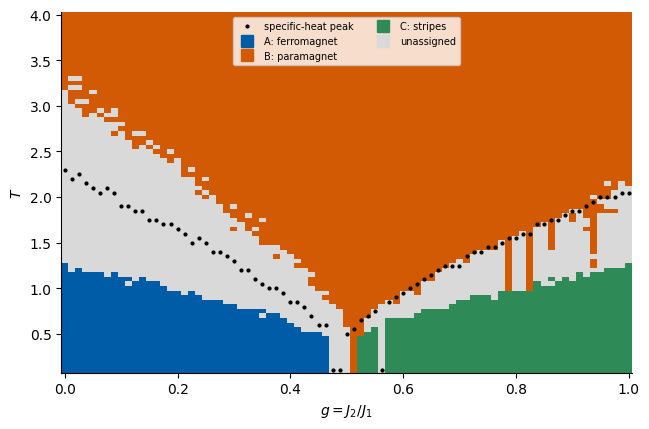

fraction of grid points: {'A: ferromagnet': 0.099, 'B: paramagnet': 0.592, 'C: stripes': 0.101, 'unassigned': 0.207}
unassigned points: g in [0.    0.012 0.025 0.038 0.05  0.062 0.075 0.088 0.1   0.112 0.125 0.138
 0.15  0.162 0.175 0.188 0.2   0.212 0.225 0.238 0.25  0.262 0.275 0.288
 0.3   0.312 0.325 0.338 0.35  0.362 0.375 0.388 0.4   0.412 0.425 0.438
 0.45  0.462 0.475 0.488 0.5   0.538 0.55  0.562 0.575 0.588 0.6   0.612
 0.625 0.638 0.65  0.662 0.675 0.688 0.7   0.712 0.725 0.738 0.75  0.762
 0.775 0.8   0.812 0.838 0.85  0.862 0.875 0.888 0.9   0.912 0.925 0.938
 0.95  0.962 0.975 0.988 1.   ] 
                   T in [0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7  0.75
 0.8  0.85 0.9  0.95 1.   1.05 1.1  1.15 1.2  1.25 1.3  1.35 1.4  1.45
 1.5  1.55 1.6  1.65 1.7  1.75 1.8  1.85 1.9  1.95 2.   2.05 2.1  2.15
 2.2  2.25 2.3  2.35 2.4  2.45 2.5  2.55 2.6  2.65 2.7  2.75 2.8  2.85
 2.9  2.95 3.   3.05 3.1  3.15 3.2  3.3 ]


In [9]:
names = list(REGIMES)
scores = []
for name in names:
    res = results[name]
    inside = res["err"][np.ix_(res["gi"], res["ti"])]
    scores.append(np.abs(res["err"] - inside.mean()) / (inside.std() + 1e-3))   # small floor: the ordered regions are almost exact
scores = np.stack(scores)                                    # (3, nG, nT)
assign = np.argmin(scores, axis=0)
assign = np.where(scores.min(0) < 3.0, assign, len(names))
colors = [REGIMES[n]["color"] for n in names] + ["#D9D9D9"]
fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.pcolormesh(G, T, assign.T, shading="nearest", cmap=ListedColormap(colors), vmin=-0.5, vmax=len(names) + 0.5)
ax.plot(G, T_c_ref, "k.", ms=4, label="specific-heat peak")
for k, n in enumerate(names + ["unassigned"]):
    ax.plot([], [], "s", color=colors[k], ms=9, label=n)
ax.set_xlabel("$g=J_2/J_1$"); ax.set_ylabel("$T$"); ax.legend(frameon=True, fontsize=7, loc="upper center", ncol=2)
fig.tight_layout(); savefig(fig, "gen_j1j2_ae_combined.png"); plt.show()
frac = {n: round(float((assign == k).mean()), 3) for k, n in enumerate(names + ["unassigned"])}
print("fraction of grid points:", frac)
un = assign == len(names)
print("unassigned points: g in", np.unique(G[np.where(un)[0]]).round(3), "\n                   T in", np.unique(T[np.where(un)[1]]).round(2))
NUMBERS["combined_fractions"] = frac

**Reading the combined map.** The three colours reproduce the three known phases. Two features need the physics to be understood:

* The **unassigned** band lies mainly on the ordered side of each transition line. There the system is ordered, but thermal fluctuations
  (flipped islands, domain walls) make the snapshots atypical for a model trained deep in the phase at $T\le1$. The band marks where the
  references stop being representative, which is the critical region and its surroundings.
* Around $g=1/2$ at the lowest temperatures the points are assigned to the **paramagnet**. That is correct physics: at the frustrated point
  the transition temperature goes to zero and the system does not order within our temperature range.

None of this used an order parameter. What it did use is a choice of reference regions, and the result depends on that choice
(regime B alone would have missed the stripe phase entirely). The physicist's job has moved, not disappeared.

<hr/>
## 5. A coarse scan, and where to measure more

The maps above used the full grid. Suppose instead we can afford only a **coarse scan**: every eighth value of $g$ ($\Delta g = 0.1$),
every eighth temperature ($\Delta T = 0.4$), and 10 snapshots per point. We train regimes A and C on the coarse data only, and look for intervals where the
error jumps. Those intervals are where a dense measurement is worth paying for.

coarse grid: 11 x 10 points x 10 snapshots = 1100 snapshots


A: ferromagnet: trained on 90 snapshots


C: stripes: trained on 90 snapshots


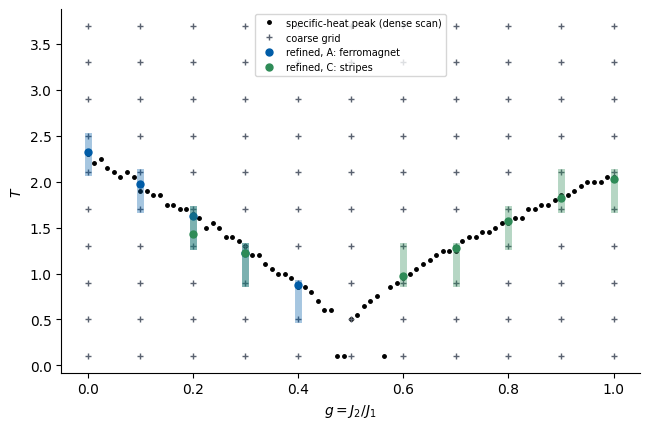

dense scan (specific heat): 639900 snapshots
coarse scan 1100 + refinement 2160 = 3260 snapshots (0.5% of the dense scan)


In [10]:
gi_c = np.arange(0, nG, 8); ti_c = np.arange(0, nT, 8)
Gc, Tc_ax = G[gi_c], T[ti_c]
S_coarse = S[np.ix_(gi_c, ti_c)][:, :, spread(nS, 10)]
print(f"coarse grid: {len(Gc)} x {len(Tc_ax)} points x 10 snapshots = {S_coarse.shape[0] * S_coarse.shape[1] * 10} snapshots")

coarse = {}
for name in ["A: ferromagnet", "C: stripes"]:
    r = REGIMES[name]
    gsel = (Gc >= r["g"][0] - 1e-9) & (Gc <= r["g"][1] + 1e-9); tsel = (Tc_ax >= r["T"][0] - 1e-9) & (Tc_ax <= r["T"][1] + 1e-9)
    X_tr = S_coarse[gsel][:, tsel].reshape(-1, L, L)
    model, _ = train_ae(X_tr, epochs=40)
    err_c = error_map(model, S_coarse, n=10)
    Tb_c, jump_c = boundary_from_map(err_c, Tc_ax)
    i = np.argmax(np.abs(np.diff(err_c, axis=1)), axis=1)
    coarse[name] = dict(model=model, err=err_c, lo=Tc_ax[i], hi=Tc_ax[i + 1], jump=jump_c, n_train=X_tr.shape[0])
    print(f"{name}: trained on {X_tr.shape[0]} snapshots")

# refinement: for every coarse g with a clear jump, measure densely (all grid temperatures in the bracket, all snapshots)
refine_cost, refined = 0, {}
for name, c in coarse.items():
    model_c = c["model"]                                   # the model trained on the coarse data only
    pts = []
    for k, gval in enumerate(Gc):
        if c["jump"][k] < JUMP_MIN: continue
        g_idx = gi_c[k]; t_idx = np.where((T >= c["lo"][k] - 1e-9) & (T <= c["hi"][k] + 1e-9))[0]
        refine_cost += len(t_idx) * N_EVAL
        e = np.array([np.asarray(recon_error(model_c, jnp.asarray(S[g_idx, j, spread(nS, N_EVAL)], jnp.float32))).mean() for j in t_idx])
        j = np.argmax(np.abs(np.diff(e)))
        pts.append((gval, 0.5 * (T[t_idx[j]] + T[t_idx[j + 1]])))
    refined[name] = np.array(pts)

fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.plot(G, T_c_ref, "k.", ms=5, label="specific-heat peak (dense scan)")
gg_, tt_ = np.meshgrid(Gc, Tc_ax, indexing="ij"); ax.plot(gg_.ravel(), tt_.ravel(), "+", color=UJGray, ms=4, label="coarse grid")
for name, c in coarse.items():
    col = REGIMES[name]["color"]; ok = c["jump"] >= JUMP_MIN
    for k in np.where(ok)[0]:
        ax.plot([Gc[k], Gc[k]], [c["lo"][k], c["hi"][k]], "-", color=col, lw=5, alpha=0.35)
    if len(refined[name]): ax.plot(refined[name][:, 0], refined[name][:, 1], "o", color=col, ms=5, label=f"refined, {name}")
ax.set_xlabel("$g=J_2/J_1$"); ax.set_ylabel("$T$"); ax.legend(frameon=True, fontsize=7, loc="upper center")
fig.tight_layout(); savefig(fig, "gen_j1j2_coarse.png"); plt.show()

dense_cost = nG * nT * nS
coarse_cost = S_coarse.shape[0] * S_coarse.shape[1] * 10
print(f"dense scan (specific heat): {dense_cost} snapshots")
print(f"coarse scan {coarse_cost} + refinement {refine_cost} = {coarse_cost + refine_cost} snapshots "
      f"({100 * (coarse_cost + refine_cost) / dense_cost:.1f}% of the dense scan)")
NUMBERS.update(cost_dense=int(dense_cost), cost_coarse=int(coarse_cost), cost_refine=int(refine_cost),
               cost_fraction=round(float((coarse_cost + refine_cost) / dense_cost), 3))

The shaded bars are the temperature brackets in which the coarse scan saw the error jump; the dots are the boundary points after measuring
densely only inside those brackets. They land on the specific-heat ridge of the dense scan at a fraction of its cost (printed above).

In an experiment this is the useful mode: a cheap survey with raw snapshots, then dense, careful measurements only where the survey says
something changes, analysed with the physicist's tools (order parameters, finite-size scaling) once we know what to look for.

<hr/>
## Summary

| method | input | what it found | compared with the known physics |
|---|---|---|---|
| PCA | all snapshots | uniform and stripe patterns as PC 1–3 | the two order parameters, exactly; works because both are linear in the spins |
| AE, regime A (ferromagnet) | snapshots from $g\le0.2,T\le1$ | the ferromagnetic boundary | on the specific-heat ridge; blind to the difference stripes/paramagnet |
| AE, regime B (paramagnet) | snapshots from $g\le0.2,T\ge3.5$ | the ferromagnetic boundary | misses the stripe phase completely |
| AE, regime C (stripes) | snapshots from $g\ge0.8,T\le1$ | the stripe boundary | on the specific-heat ridge |
| AE, combined | three regimes | three phases + an unassigned region | unassigned: the frustrated region near $g=1/2$ and the transition lines |

> **Try it.**
> 1. Train regime B with a larger latent space (16 numbers). Does the stripe phase become visible?
> 2. Choose a training region in the *middle* of the stripe phase ($0.7\le g\le0.9$, $0.5\le T\le1.0$) instead of a corner.
> 3. Replace the reconstruction error by the distance in latent space to the training data (mean distance to the 10 nearest training
>    latent vectors). Compare the boundaries.

<hr/>
## References

* K. Kottmann, P. Huembeli, M. Lewenstein, A. Acín, *Unsupervised phase discovery with deep anomaly detection*, Phys. Rev. Lett. **125**, 170603 (2020), [arXiv:2003.09905](https://arxiv.org/abs/2003.09905)
* L. Wang, *Discovering phase transitions with unsupervised learning*, Phys. Rev. B **94**, 195105 (2016), [doi:10.1103/PhysRevB.94.195105](https://doi.org/10.1103/PhysRevB.94.195105)
* W. Hu, R. R. P. Singh, R. T. Scalettar, *Discovering phases, phase transitions, and crossovers through unsupervised machine learning: A critical examination*, Phys. Rev. E **95**, 062122 (2017), [arXiv:1704.00080](https://arxiv.org/abs/1704.00080)
* Physics of the model: A. Kalz et al., Eur. Phys. J. B **65**, 533 (2008), [arXiv:0805.0983](https://arxiv.org/abs/0805.0983); S. Jin, A. Sen, A. W. Sandvik, Phys. Rev. Lett. **108**, 045702 (2012), [arXiv:1110.5874](https://arxiv.org/abs/1110.5874)

In [11]:
with open(f"{FIG}/numbers_lab020.json", "w") as f:
    json.dump(NUMBERS, f, indent=1)
print(json.dumps(NUMBERS, indent=1))

{
 "pca_var": [
  0.1659,
  0.0839,
  0.0822,
  0.0031,
  0.003,
  0.0028
 ],
 "pca_overlaps": [
  [
   1.0,
   0.001,
   0.001
  ],
  [
   0.001,
   1.0,
   0.024
  ],
  [
   0.001,
   0.024,
   1.0
  ],
  [
   0.001,
   0.0,
   0.0
  ]
 ],
 "pca_corr_m": 1.0,
 "pca_corr_mstr": 0.9999,
 "ae_boundary_vs_C": {
  "A: ferromagnet": {
   "n_points": 39,
   "median_abs_dev": 0.025,
   "g_range": [
    0.0,
    0.475
   ]
  },
  "B: paramagnet": {
   "n_points": 39,
   "median_abs_dev": 0.025,
   "g_range": [
    0.0,
    0.4875
   ]
  },
  "C: stripes": {
   "n_points": 40,
   "median_abs_dev": 0.025,
   "g_range": [
    0.5125,
    1.0
   ]
  }
 },
 "combined_fractions": {
  "A: ferromagnet": 0.099,
  "B: paramagnet": 0.592,
  "C: stripes": 0.101,
  "unassigned": 0.207
 },
 "cost_dense": 639900,
 "cost_coarse": 1100,
 "cost_refine": 2160,
 "cost_fraction": 0.005
}
